# **1. Problem Framing and Hypotheses**

## **1.1 O Contexto do Problema**

### **As decisões**

Perante a Sofia estão diversas decisões, a vários níveis:

- **Definição de objetivos:** existem três opções principais: prever que colaboradores têm intenção de sair; descobrir que fatores são mais preponderantes no nível de exaustão; ou segmentar os colaboradores em perfis.
- **Nível metodológico:** serão tomadas decisões relativas ao tratamento dos dados, tais como o preenchimento de *missing values*, a substituição de valores evidentemente errados (ex.: idade = 2) ou o tratamento dado a informações de foro pessoal, como idade, género ou a existência de filhos.
- **Estratégia de intervenção:** terá de ser elaborada uma estratégia ao nível das aplicações internas para colaboradores que, procurando satisfazer as necessidades dos mesmos e reduzir o *turnover*, não comprometa questões éticas nem recorra a *dark patterns*.

### **Os stakeholders**

A estratégia a adotar depende das necessidades e objetivos de diferentes stakeholders:

- **Os 3 diretores de RH**, que pretendem principalmente reduzir os custos associados ao *turnover*. Apesar de partilharem este objetivo, bem como um alinhamento comum com as práticas da Indústria 5.0, podem ter interesses competitivos distintos, e existe uma preocupação manifesta com o respeito por princípios éticos nas estratégias de retenção.
- **Os colaboradores**, que, para além de beneficiarem de uma alocação mais eficiente de recursos em programas de retenção, podem estar expostos a riscos através dos dados pessoais disponibilizados, ou devido a eventuais medidas de intervenção mais predatórias (*dark patterns*).

### **O mesmo conjunto de dados, 3 empresas**

A criação de um dataset comum apresenta benefícios, mas também limitações. Permite, por um lado, aplicar de forma mais eficaz métodos que necessitam de grandes volumes de dados, como o *machine learning*. Por outro lado, as conclusões obtidas serão mais generalistas para o mercado em estudo e não necessariamente aplicáveis a necessidades concretas de uma empresa em particular, uma vez que não existe identificador de empresa.

---

## **1.2 Framing & Hypotheses**

### **A questão central**

No problema em estudo, o principal objetivo será prever, a partir dos dados do questionário, quais os colaboradores que apresentam risco de abandonar a empresa e quais são os principais fatores que motivam este risco. Para isso, será selecionada uma variável target, e, dado o volume de dados, construir-se-á um modelo de machine learning para classificação.

### **Target**
Ao definir qual deve ser a variável *target* a prever pelo modelo, há que considerar que as opções disponíveis (*exhaustion*, *intention to look for a new job* e *intention to quit*) representam um *pipeline* claro na evolução da vontade do colaborador em abandonar a empresa. Isto é, um colaborador exausto começará a procurar novas oportunidades e, eventualmente, irá manifestar vontade de abandonar a empresa.

Atuar em pontos diferentes deste *pipeline* poderá produzir efeitos distintos. Por exemplo, se um colaborador exausto for identificado, poderá ser "recaptado" antes de manifestar intenções mais "sérias" de saída. Por outro lado, a exaustão pode ser um indicador pouco robusto, uma vez que não responde diretamente ao problema "quem pretende sair".

### **Comparação dos possíveis targets**

| Target | Vantagens | Desvantagens |
|---|---|---|
| **`intention_quit`** | Mais próximo do comportamento real de saída e da pergunta dos diretores ("quem vamos perder?"). Fácil de comunicar e de transformar numa lista acionável. | Média baixa (2,64 numa escala de 1-7), logo poucos casos "em risco" e classes desbalanceadas. Sinal mais tardio: quem já decidiu sair é mais difícil de reter. |
| **`intention_lookfornewjob`** | Sinal mais precoce, portanto mais acionável (ainda há margem para intervir). Média ligeiramente mais alta (2,90), com menor desbalanceamento. | Procurar emprego não implica sair (pode ser curiosidade ou negociação). Proxy mais ruidoso do *turnover* real. Provavelmente muito correlacionada com `intention_quit`. |
| **`Exhaustion`** | Distribuição mais equilibrada e mais "contínua". Muito acionável (carga de trabalho, bem-estar). Sinal ainda mais precoce no *pipeline*. | Não responde diretamente à pergunta do caso: é um estado e não uma decisão. Teoricamente é mais um *driver* (ou mediador) do que o resultado final. Escala diferente das restantes (1-5, com 5 = pior). |

**Escolha e papel das restantes variáveis:** o *target* principal será `intention_lookfornewjob`, por constituir uma variável de compromisso: suficientemente próxima da decisão de saída, mas num ponto do *pipeline* em que ainda é possível intervir. A `intention_quit` será excluída das *features* (para evitar *data leakage*, por ser quase uma reformulação do *target*). A `Exhaustion` será mantida como variável (burnout → intenção de procurar emprego). 

### **Tratamento do target como variável binária**

Para efeitos operacionais ("quem está em risco?"), o *target* será transformado numa variável binária, em que valores abaixo de um determinado limiar correspondem a "sem risco" (0) e valores iguais ou acima a "em risco" (1). Esta opção facilita a comunicação e a ação por parte dos diretores, bem como a utilização de métricas próprias de modelos de classificação (*recall*, *precision*, F1, ROC-AUC).

No entanto, esta simplificação implica perder alguma **sensibilidade** da escala ordinal original (1-7): colaboradores com respostas muito próximas, mas em lados opostos do limiar, passam a ser tratados como completamente diferentes, e a escolha do limiar é, por natureza, algo arbitrária. Este efeito será averiguado na **análise de thresholds**, na qual a coluna original (1-7) será mantida intacta e o limiar será tratado como um parâmetro, repetindo o treino e a avaliação para vários cortes (por exemplo, ≥ 3, ≥ 4 e ≥ 5) e verificando se o desempenho e os principais *drivers* se mantêm estáveis.

### **Hipóteses a Testar**

| ID | Hipótese | Variáveis a testar | Relação esperada |
|---|---|---|---|
| H1 | **Clima organizacional:** Uma perceção mais positiva do clima organizacional (confiança, comunicação, justiça e camaradagem) está associada a uma menor intenção de procurar um novo emprego. | `ca_camaraderie`, `ca_leaders_credibility`, `ca_leader_communication`, `ca_personal_development`, `ca_fairness`, `ca_work_family_balance` | Negativa |
| H2 | **Características do trabalho:** Características profissionais mais favoráveis (variedade de competências, identidade e significado das tarefas, autonomia e feedback) estão associadas a uma menor intenção de procurar um novo emprego. | `Skill_Variety`, `Task_Identity`, `Task_Significance`, `Autonomy`, `Feedback` | Negativa |
| H3 | **Exaustão:** Níveis mais elevados de exaustão dos colaboradores estão associados a uma maior intenção de procurar um novo emprego. | `Exhaustion` | Positiva |
| H4 | **Desenvolvimento profissional:** Uma menor perceção de oportunidades de desenvolvimento pessoal e progressão na carreira está associada a uma maior intenção de procurar um novo emprego. | `ca_personal_development`, `n_progressions`, `years_in_position` | Negativa* |
| H5 | **Antiguidade:** A antiguidade na empresa e na função está associada à intenção de procurar um novo emprego, podendo existir uma relação não linear. | `years_in_company`, `years_in_position` | Não linear** |
| H6 | **Formação e progressão:** Colaboradores com mais formação e progressões na carreira tendem a apresentar uma menor intenção de procurar um novo emprego. | `training` (3 variáveis), `n_progressions` | Negativa |
| H7 | **Fatores sociodemográficos:** A intenção de procurar um novo emprego apresenta diferenças entre grupos sociodemográficos, nomeadamente em função da idade e do género. | `age`, `is_female` | Exploratória*** |

**Notas sobre as relações esperadas:**

- *H4: Espera-se uma relação negativa entre a perceção de oportunidades de desenvolvimento e a intenção de procurar emprego.
- **H5: Não se assume uma relação linear. Uma maior antiguidade poderá estar associada a uma menor intenção de saída, devido à integração e estabilidade profissional. Contudo, poderá também existir um aumento da intenção de saída em situações de estagnação profissional.
- ***H7: Não se define antecipadamente uma direção para a relação. Diferenças entre grupos etários ou de género serão investigadas empiricamente, sem assumir que determinado grupo apresenta necessariamente maior intenção de saída.


# **2.Data quality and cleaning**


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

#Carregar os dados do ficheiro people_operations_dataset
df = pd.read_excel("people_operations_dataset.xlsx", sheet_name="dataframe")

#Missing values por coluna (n e %), ordenado do maior para o menor
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100),
}).sort_values("pct_missing", ascending=False)

#Visão por linha: quantas linhas são afetadas e com quantos missing cada uma
rows_with_na = df.isna().any(axis=1).sum()
print(f"Linhas com pelo menos 1 missing: {rows_with_na} de {len(df)} "
      f"({rows_with_na / len(df) * 100:.1f}%)")
print(f"Linhas completas: {len(df) - rows_with_na}")

na_per_row = df.isna().sum(axis=1).value_counts().sort_index()
na_per_row.name = "n_linhas"
na_per_row.index.name = "n_missing_na_linha"
display(na_per_row)

#Gráfico: % de missing por coluna (só colunas com missing)
to_plot = missing[missing["pct_missing"] > 0].sort_values("pct_missing")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(to_plot.index, to_plot["pct_missing"])
ax.set_xlabel("% de valores em falta")
ax.set_title("Valores em falta por variável")
for i, v in enumerate(to_plot["pct_missing"]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=8)

#Gráfico: % de linhas com X colunas missing
pct_rows = na_per_row / len(df) * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(na_per_row.index.astype(str), pct_rows.values)

ax.set_xlabel("Nº de colunas em falta na linha")
ax.set_ylabel("% de linhas")
ax.set_title("Valores em falta por linha")

# percentagem em cima de cada barra
for bar, p in zip(bars, pct_rows.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{p:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
import math

# Variáveis com missing que são numéricas (as categóricas usam a moda)
cat_cols = ["marital status", "position_in_Company"]
num_cols = [c for c in df.columns if df[c].isna().any() and c not in cat_cols]

# 1. Tabela resumo: quão diferentes são média e mediana?
summary = pd.DataFrame({
    "n_missing": df[num_cols].isna().sum(),
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "desvio_padrao": df[num_cols].std(),
    "assimetria": df[num_cols].skew(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
})
summary["|media-mediana|/desvio"] = (
    (summary["media"] - summary["mediana"]).abs() / summary["desvio_padrao"]
)
display(summary.sort_values("assimetria", key=abs, ascending=False).round(2))

# 2. Histogramas com média (vermelho, tracejado) e mediana (verde)
n_cols_grid = 4
n_rows_grid = math.ceil(len(num_cols) / n_cols_grid)
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(16, 3.3 * n_rows_grid))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    data = df[col].dropna()
    ax.hist(data, bins=min(20, data.nunique()), color="lightsteelblue", edgecolor="white")
    ax.axvline(data.mean(), color="red", linestyle="--", label=f"Média: {data.mean():.2f}")
    ax.axvline(data.median(), color="green", linestyle="-", label=f"Mediana: {data.median():.2f}")
    ax.set_title(f"{col}\n(assimetria = {data.skew():.2f})", fontsize=10)
    ax.set_ylabel("Nº de respostas")
    ax.legend(fontsize=7)

for ax in axes[len(num_cols):]:   # esconder subplots vazios
    ax.axis("off")

fig.suptitle("Distribuição das variáveis com missing: média vs mediana", fontsize=14)
plt.tight_layout()
plt.show()

## **2.1 Identificação e Tratamento de Missing Values**

O primeiro passo na preparação de dados corresponde à identificação dos *missing values* no dataset. Para isso, elaborou-se o gráfico de barras que mostra, por ordem decrescente, as variáveis com maior percentagem de *missing values*.

Através do mesmo, conclui-se que as variáveis com maior percentagem de *missing values* são "Leader Communication", "Personal Development" e "Work Family", com mais de 10% dos valores em falta.

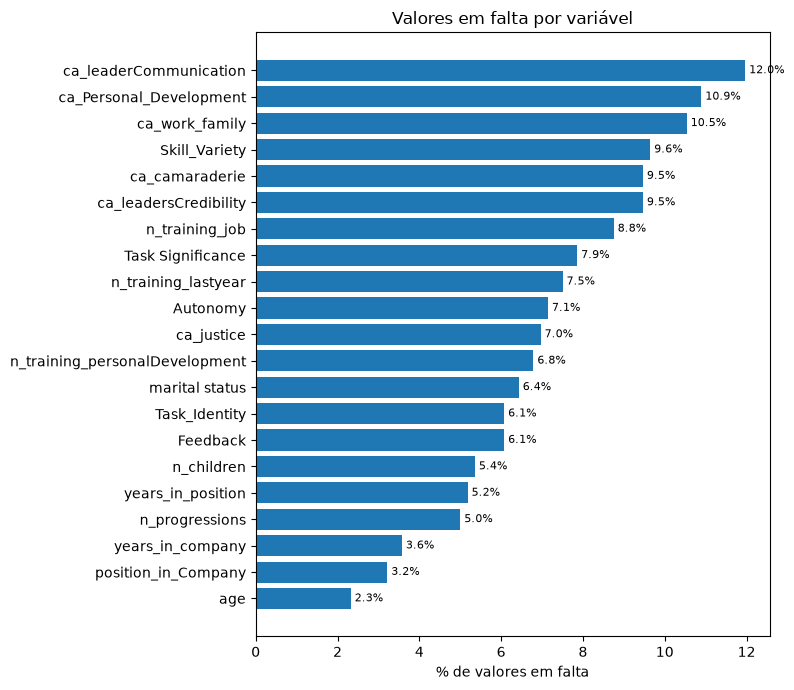

É interessante notar também que cerca de 75% das linhas têm entre 1 e 3 colunas sem valores, e que cerca de 20% do total não tem qualquer *missing value*. Assim, a estratégia mais adequada para tratar os *missing values* não será a eliminação (uma vez que isso implicaria eliminar 80% das linhas), mas sim a imputação.

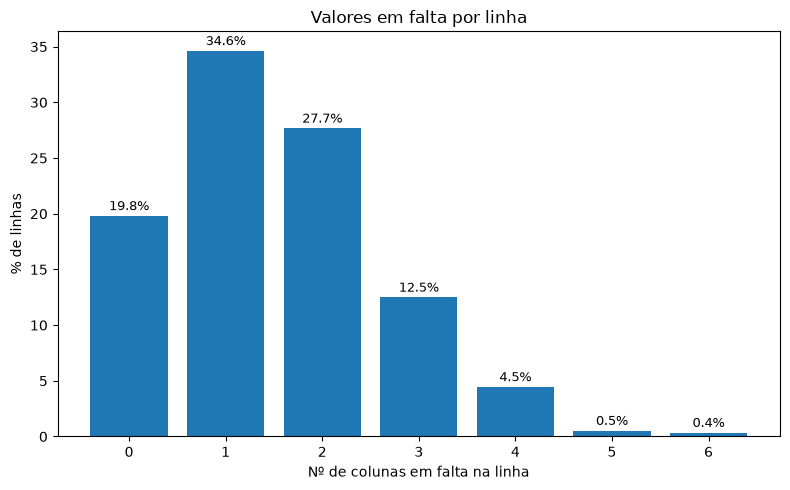

### **Estratégia de imputação**

Dado que nenhuma variável tem mais de 12% de valores em falta, é aceitável recorrer a uma imputação simples, através de medidas de tendência central. Uma vez que a grande maioria das variáveis foi medida em escalas discretas ou corresponde a contagens com distribuição assimétrica, a média seria pouco adequada: nas escalas, pode produzir valores que não existem na escala de resposta e, nas contagens, é influenciada por poucos casos extremos. Recorrer-se-á, por isso, à **mediana**, que é também mais robusta a valores atípicos.

Exceção feita às variáveis "Estado Civil" (`marital status`) e "Posição na Empresa" (`position_in_Company`) que, por estarem associadas a códigos categóricos, serão imputadas com recurso à **moda**.

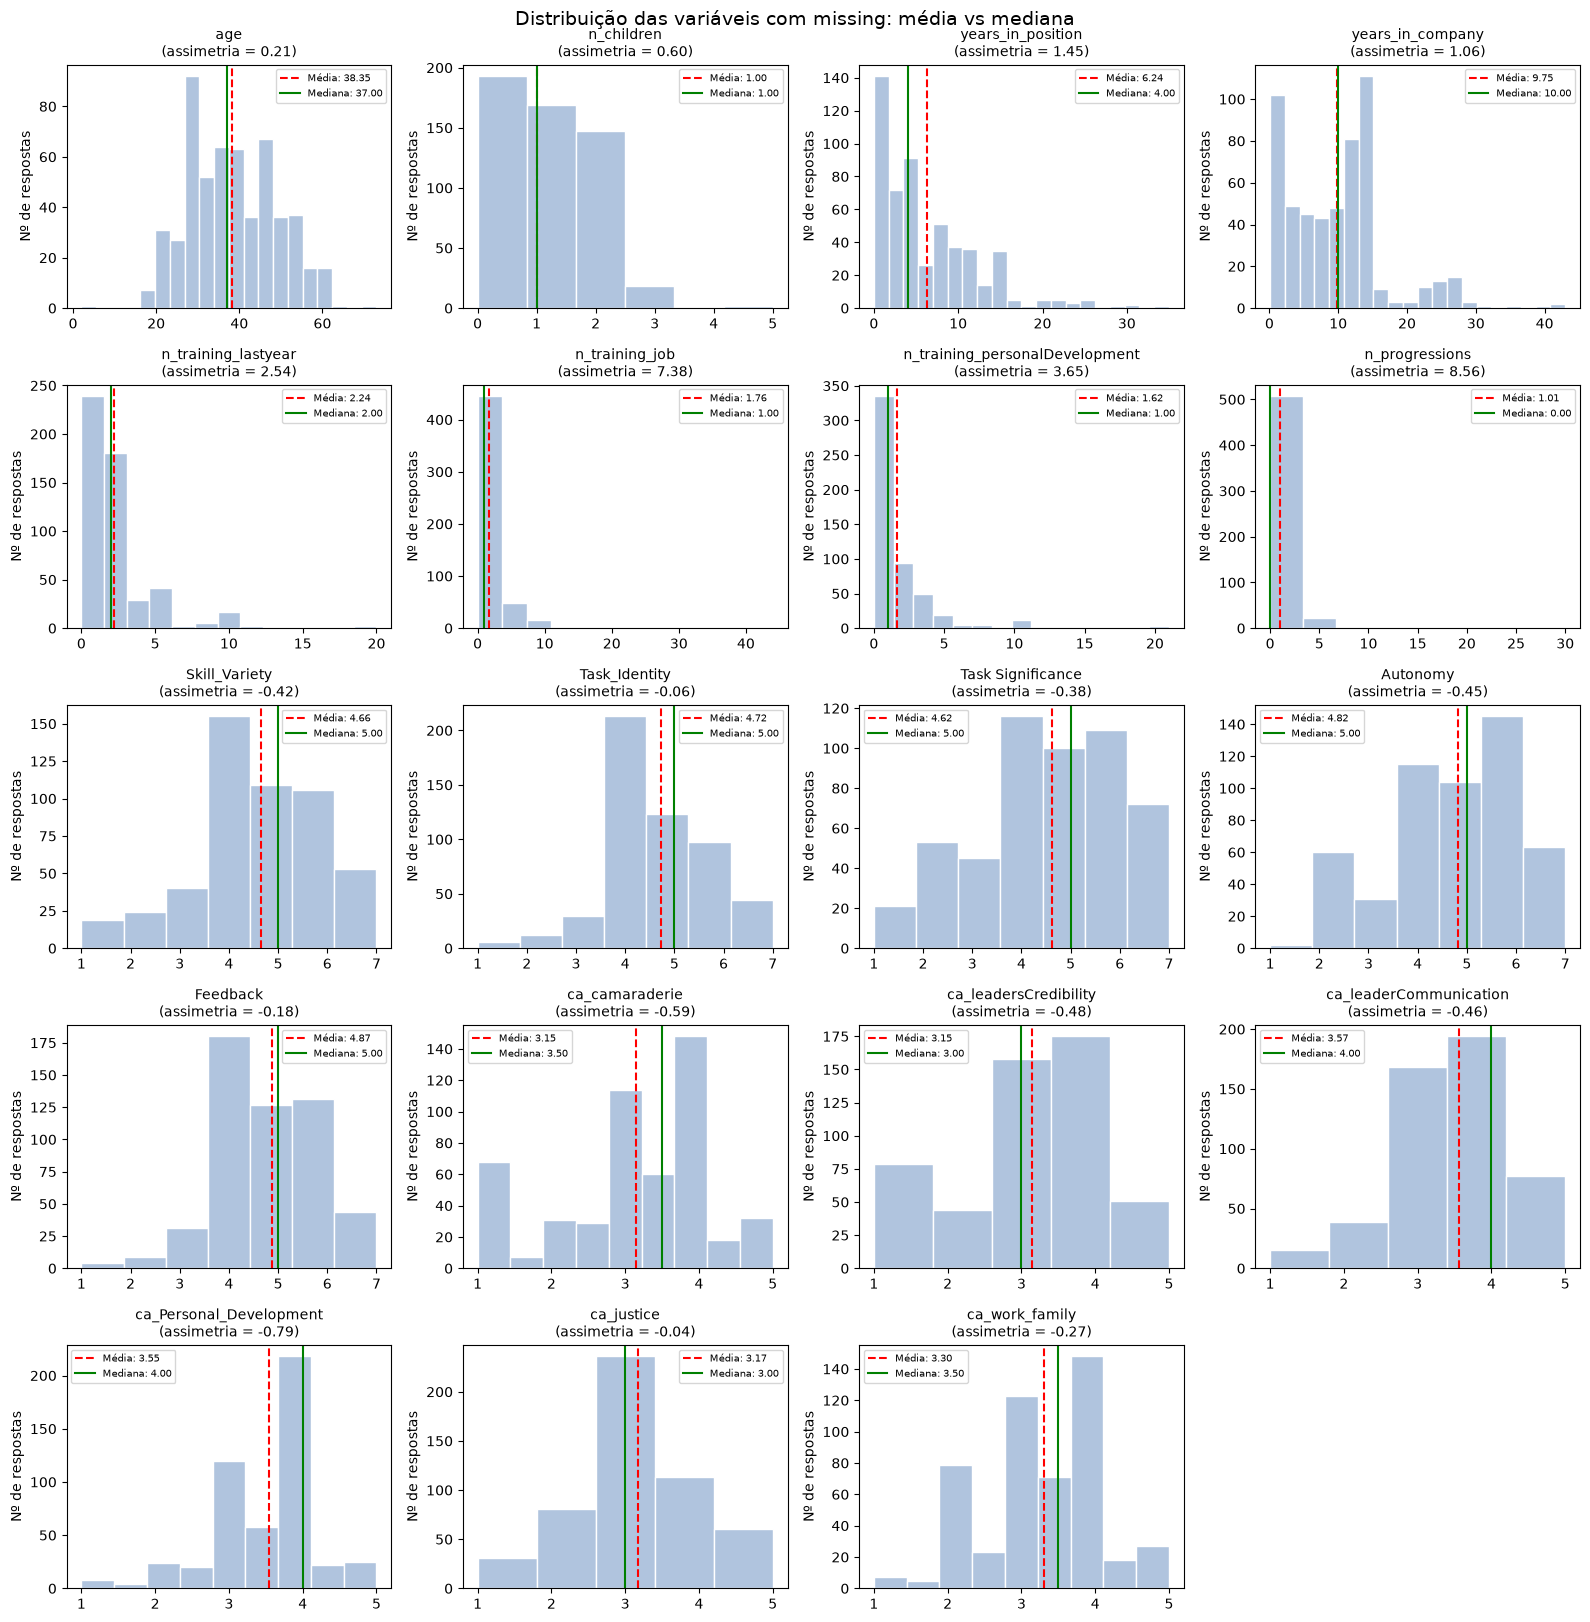

### **Perda de informação**

A imputação pela mediana (ou moda) atribui o mesmo valor a todos os casos em falta de uma variável, o que implica perda de informação. Por um lado, concentra os valores no centro da distribuição, reduzindo a variabilidade e enfraquecendo ligeiramente as correlações entre variáveis e com o *target*, o que pode levar a subestimar algumas associações testadas nas hipóteses. Por outro, ignora a relação com as restantes respostas do colaborador (por exemplo, o seu valor nos outros itens de clima) e assume que a ausência de resposta é aleatória: se os colaboradores que não respondem forem sistematicamente diferentes (por exemplo, mais desligados da empresa), a imputação não recupera esse sinal e pode introduzir enviesamento. No caso da moda, a categoria mais frequente é ainda reforçada.

Estes efeitos são atenuados pela baixa proporção de valores em falta (cerca de 5% das células e no máximo 12% por variável). Na fase de modelação, a imputação será ajustada apenas nos dados de treino, para evitar fuga de informação para o teste.



In [ ]:
# Boxplots para variáveis de contagem e anos
cols_box = ["age", "years_in_company", "years_in_position",
            "n_training_lastyear", "n_training_job",
            "n_training_personalDevelopment", "n_progressions", "n_children"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), cols_box):
    ax.boxplot(df[col].dropna(), vert=True)
    ax.set_title(col, fontsize=10)
plt.suptitle("Boxplots: identificação de outliers", fontsize=14)
plt.tight_layout()
plt.show()

# Verificações de consistência de idade, anos na posicao e anos na empresa
print("Posição > empresa:", (df["years_in_position"] > df["years_in_company"]).sum())
display(df[df["years_in_company"] > df["age"] - 16][["indice", "age", "years_in_company", "years_in_position"]])
print("Fora da escala (Likert):")
likert = ["Skill_Variety", "Task_Identity", "Task Significance", "Autonomy", "Feedback",
          "ca_camaraderie", "ca_leadersCredibility", "ca_leaderCommunication",
          "ca_Personal_Development", "ca_justice", "ca_work_family"]
display(df[likert].agg(["min", "max"]).T)

In [ ]:
#Despiste para ver se os erros da linha 18 se repetiam

for c in ["is_office", "is_female", "has_children"]:
    print(c, df[c].value_counts(dropna=False).sort_index().to_dict())

print("indice duplicados:", df["indice"][df["indice"].duplicated(keep=False)].tolist())
display(df.loc[[5, 16]].T)

## **2.2 Identificação e Tratamento de Outliers**

A próxima etapa no tratamento de dados consiste na indetificação de outliers. Aqui, tomou-se como outliers não apenas os valores que diferem substancialmente da tendência do conjunto mas principalmente valores irrealista ou impossíveis. Este tratamento visa sobretudo parâmetros que expressam anos, como a Idade, ou mesmo inconsistências entre duas variáveis como número de anos na empresa e número de anos na mesma posição.

### **As variáveis potencialmente problemáticas**
**Idade**: Na idade, foram detetados exatamente dois outliers, colaborador com 2 anos e um com 73 anos. Relativamente ao último, uma vez que tem a sua função classificada como 5, assume-se que se trata de um gestor ou diretor de alto nível, pelo que se admite como um dado válido.
Por outro lado, o colaborador identificado com idade = 2 apresenta diversos registos "estranhos" em diferentes parâmetros. Primeiramente, apresenta um índice incorreto e ainda valor 3 na variável binária "in_office" tal como acontece na variável binária "is_female" onde o valor é 5. Uma pesquisa generalizada no dataset para valores incorretos nestas variáveis binárias revelou que este foi o único registo onde tal se verificou.
Dadas estas imprecisões, opta-se por remover a linha 18 do ficheiro excel, de modo a reduzir o ruído do dataset. 

**Years_in_company/years_in_position**: Nestas variáveis, procurou-se encontrar imprecisões em que o tempo de permanência numa posição é superior ao tempo de permanência na empresa, algo ilógico, tal como situações em que o tempo na empresa, quando subtraído à idade do colaborador conduz a valores pouco coerentes. Neste âmbito, utilizou-se como threshold o valor mínimo legal para exercer uma profissão em Portugal, que é de 16 anos.
Foram identificadas 15 ocorrências de colaboradores, em que os anos na posição superam os anos na empresa, tendo-se optado por igualar ambos os parâmetros ao menor valor de entre ambos (Por exemplo se a variável "years_in_position" tiver um valor de 21 atribuído, e a variável "years_in_company" apenas de 10, a primeira variável será igualada a este último valor).
Com o limiar de 16 anos, foram identificados 2 casos em que a antiguidade na empresa não é compatível com o limiar de 16 anos. Contudo, uma vez que a idade estimada de entrada na empresa, destes dois casos, é de 15 anos, opta-se pela não remoção dos dados.

**N_training / n_progressions**: nestas variáveis de contagem, a distribuição é fortemente assimétrica, com a maioria dos valores entre 0 e 10. Optou-se por não eliminar linhas, uma vez que isso implicaria perder informação das restantes variáveis para corrigir um único campo. Foram tratados como valores implausíveis, passando a *missing* e sendo posteriormente imputados pela mediana, apenas dois casos: `n_progressions = 30` (30 progressões em 14 anos de empresa, quando o valor seguinte mais alto é 7) e `n_training_job = 44` (mais do dobro do segundo maior valor e incoerente com as restantes variáveis de formação do mesmo colaborador). Os restantes valores elevados (por exemplo, 10 e 20 formações) foram mantidos por serem plausíveis, e repetem-se com frequência, o que sugere estimativas arredondadas.

**N_children**: nesta variável, 30 registos têm valor em falta. Em 13 deles, a variável `has_children` indica que o colaborador não tem filhos, pelo que o valor em falta foi preenchido com 0, por dedução lógica e não por imputação estatística. Nos restantes 17 casos (`has_children = 1`), aplicou-se a imputação pela mediana, que resulta em 1 e é coerente com a existência de filhos.

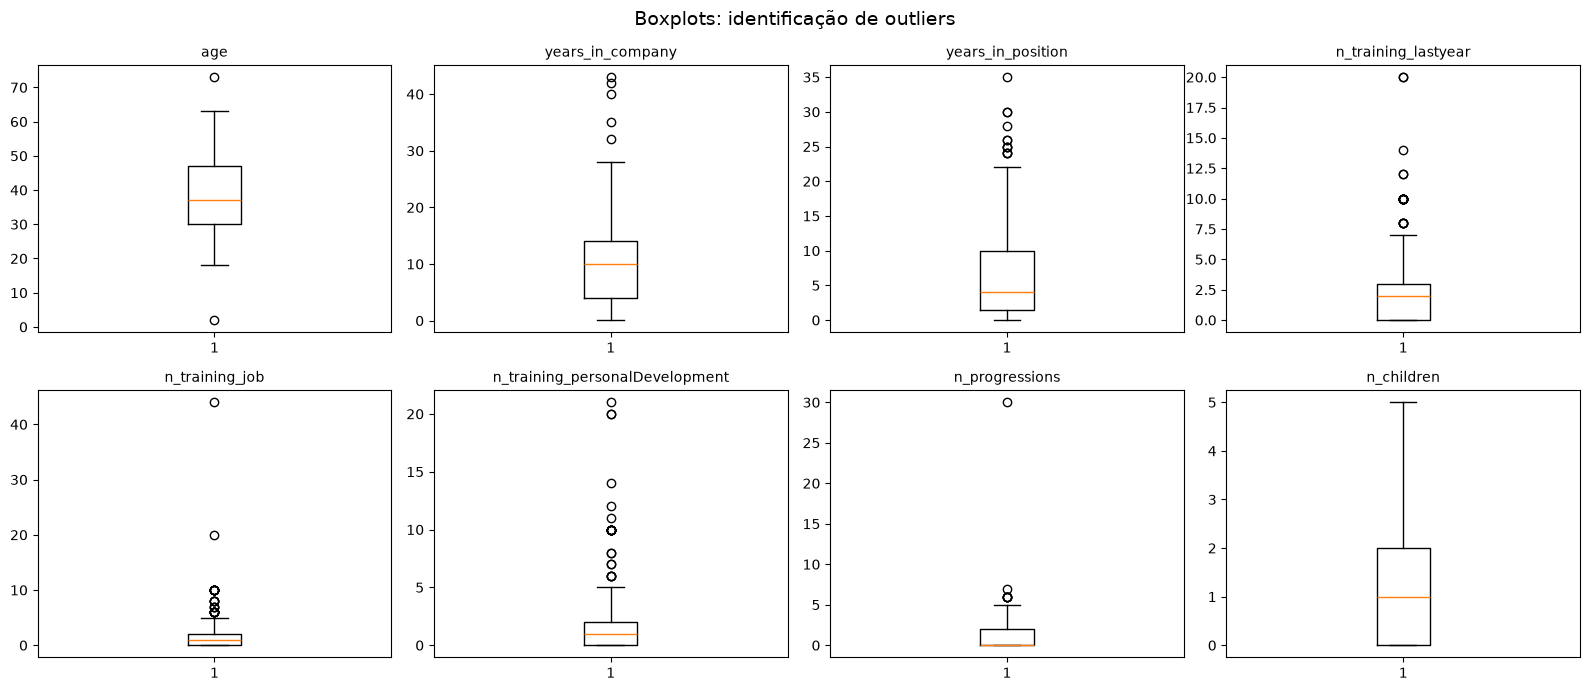

In [ ]:
import numpy as np

df_clean = df.copy()

#Remoção da linha corrompida (índice duplicado, is_office=3, is_female=5, age=2)
df_clean = df_clean.drop(index=16)

#Posição não pode exceder antiguidade na empresa
mask = df_clean["years_in_position"] > df_clean["years_in_company"]
df_clean.loc[mask, "years_in_position"] = df_clean.loc[mask, "years_in_company"]

#Outliers claramente implausíveis passam a missing (são substituidos pela mediana mais abaixo)
df_clean.loc[df_clean["n_progressions"] > 20, "n_progressions"] = np.nan
df_clean.loc[df_clean["n_training_job"] > 40, "n_training_job"] = np.nan

#n_children: sem filhos passa a 0
mask0 = df_clean["has_children"].eq(0) & df_clean["n_children"].isna()
df_clean.loc[mask0, "n_children"] = 0

#Imputação das duas variáveis de anos, respeitando tempo na posicao <= tempo na empresa
med_emp = df_clean["years_in_company"].median()
med_pos = df_clean["years_in_position"].median()
df_clean["years_in_company"] = df_clean["years_in_company"].fillna(
    np.maximum(med_emp, df_clean["years_in_position"].fillna(0)))
df_clean["years_in_position"] = df_clean["years_in_position"].fillna(
    np.minimum(med_pos, df_clean["years_in_company"]))

#Imputação das restantes: mediana (numéricas/ordinais) e moda (categóricas)
cat_cols = ["marital status", "position_in_Company"]
num_cols = [c for c in df_clean.columns if df_clean[c].isna().any() and c not in cat_cols]
for c in num_cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())
for c in cat_cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])

#Verificações finais
print("Shape:", df_clean.shape, "| missing restantes:", df_clean.isna().sum().sum())
print("Posição > empresa:", (df_clean["years_in_position"] > df_clean["years_in_company"]).sum())

# **3. Exploratory Data Analysis**

In [ ]:
import seaborn as sns

target = "intention_lookfornewjob"
quit_col = "intention_quit"

#Distribuição de intention_lookfornewjob
dist = df_clean[target].value_counts().sort_index()
pct = dist / len(df_clean) * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(dist.index.astype(str), pct.values)
for bar, p in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{p:.1f}%", ha="center", fontsize=9)
ax.set_xlabel("Intenção de procurar novo emprego (1-7)")
ax.set_ylabel("% de colaboradores")
ax.set_title("Distribuição de intention_lookfornewjob")
plt.tight_layout()
plt.show()

#% com intenção clara de sair (quit >= 5) por nível de look for new job
share = df_clean.groupby(target)[quit_col].apply(lambda s: (s >= 5).mean() * 100)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(share.index.astype(str), share.values)
for bar, p in zip(bars, share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f"{p:.0f}%", ha="center", fontsize=9)
ax.set_xlabel("intention_lookfornewjob")
ax.set_ylabel("% com intention_quit ≥ 5")
ax.set_title("Intenção clara de sair (quit ≥ 5) por nível de procura de emprego")
plt.tight_layout()
plt.show()



## **3.1 Transformação da Variável Target numa Variável Binária**

Como referido anteriormente, pretende-se conceber um modelo do tipo classificador para identificar que colaboradores apresentam maior risco de sair, através da variável `intention_lookfornewjob`. Assim, é necessário transformar esta variável, medida numa escala ordinal (1-7), numa variável binária (0 = não revela intenções sérias de sair; 1 = revela intenções sérias de sair).

Para estabelecer o limiar de decisão é necessário recordar o objetivo da escolha desta variável como *target*: identificar colaboradores que apresentam uma propensão forte a querer sair, mas num ponto do *pipeline* em que as medidas a tomar (melhoria das *features* das aplicações empresariais) ainda poderão produzir efeito nesta decisão.

### **Distribuição do target**

A distribuição de `intention_lookfornewjob` é assimétrica, concentrando-se nos valores mais baixos: 58,6% dos colaboradores respondem 1 ou 2, e apenas 16,5% respondem 5 ou mais.

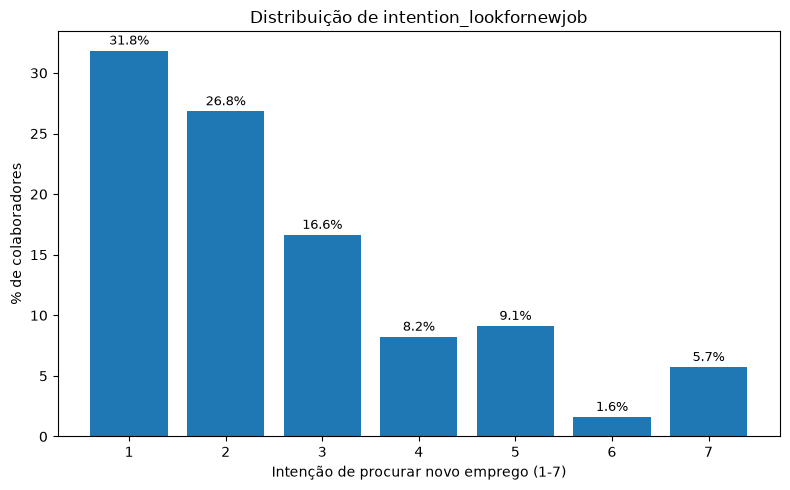

| Limiar (≥) | Colaboradores em risco | % do total |
|---|---|---|
| 3 | 231 | 41,3% |
| 4 | 138 | 24,7% |
| 5 | 92 | 16,5% |

### **Cruzamento com `intention_quit`**

Para fundamentar o limiar, cruzou-se `intention_lookfornewjob` com `intention_quit`, que mede um passo seguinte no *pipeline* (a intenção de sair). A percentagem de colaboradores com intenção clara de sair (`intention_quit` ≥ 5) aumenta com o nível de procura de emprego: ronda os 9% nos níveis 1 e 2, 30-35% nos níveis 3 e 4, e passa para cerca de 70% ou mais a partir do nível 5.

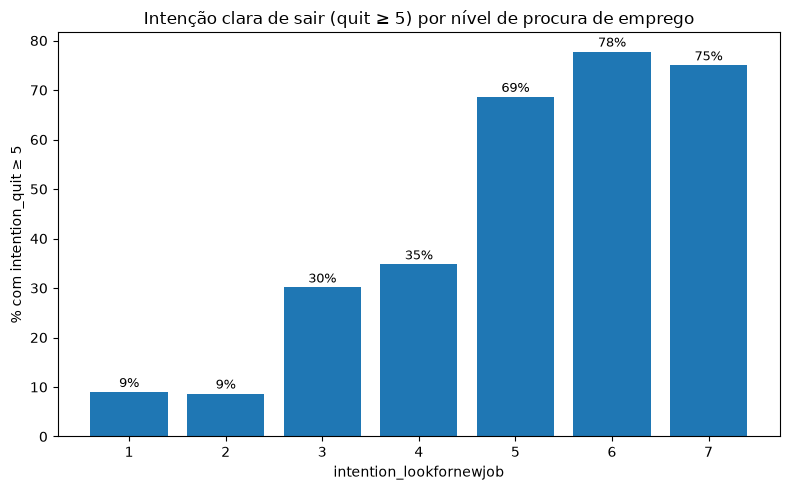

Com o limiar ≥ 4, 59% dos colaboradores identificados têm `intention_quit` ≥ 5 e apenas 19% têm `intention_quit` < 4. Com o limiar ≥ 5, a primeira percentagem sobe para 72%, mas apenas 47,5% de todos os colaboradores com intenção clara de sair são identificados (contra 59% com o limiar ≥ 4). Note-se ainda que a variável `intention_quit` apresenta um pico no valor 4 (150 respostas, contra 46 no valor 3 e 72 no valor 5), que pode refletir uma tendência para a resposta neutra no ponto médio da escala, pelo que este valor não é usado como critério de referência.

### **Decisão**

Optou-se pelo limiar **`intention_lookfornewjob` ≥ 4**. Esta escolha justifica-se por:

- **Antecedência:** limiares mais elevados correspondem a colaboradores mais avançados no *pipeline* e com menor margem para intervenção.
- **Custo assimétrico dos erros:** as intervenções previstas (*nudges* nas aplicações internas) são de baixo custo, pelo que um falso positivo custa pouco face a um falso negativo (um colaborador que sai sem ter sido sinalizado).
- **Equilíbrio de classes:** 24,7% de colaboradores em risco é mais adequado para treinar e avaliar o modelo do que 16,5%.

O nível 4 corresponde a uma zona intermédia (apenas 35% dos colaboradores neste nível têm `intention_quit` ≥ 5), que se assume deliberadamente como sinal precoce e não como decisão tomada.

### **Limitações e análise de sensibilidade**

O limiar é uma escolha em parte arbitrária e implica perder a granularidade da escala ordinal original: colaboradores com respostas muito próximas, mas em lados opostos do limiar, passam a ser tratados como completamente diferentes. Além disso, trata-se de intenções autorreportadas, medidas no mesmo momento, e não de saídas reais. A calibração com `intention_quit` serve como apoio, mas torna a definição de "em risco" parcialmente dependente dessa variável.

Por estes motivos, a coluna original (1-7) é mantida intacta e o limiar é tratado como um parâmetro: na fase de modelação, o treino e a avaliação serão repetidos para os limiares 3, 4 e 5, comparando as métricas e a estabilidade dos principais *drivers*.

In [ ]:
# 3. Heatmap de correlações (Spearman)
# Excluir o identificador e as categóricas nominais (a ordem dos códigos não tem significado)
excluir = ["indice", "marital status", "position_in_Company"]
cols = [c for c in df_clean.columns if c not in excluir]
corr = df_clean[cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))   # mostrar só o triângulo inferior
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 6},
            cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.3, ax=ax)
ax.set_title("Correlações de Spearman")
plt.tight_layout()
plt.show()



In [ ]:

# Imports comuns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint

# Criação da variável target binária (a coluna original é mantida intacta)
LIMIAR = 4   # parâmetro: repetir com 3 e 5 na análise de sensibilidade
df_clean["em_risco"] = (df_clean["intention_lookfornewjob"] >= LIMIAR).astype(int)

def risco_por_faixa(df, var, q=5):
    faixas = pd.qcut(df[var], q=q, duplicates="drop")
    g = df.groupby(faixas, observed=True)["em_risco"].agg(["sum", "count"])
    g["taxa"] = g["sum"] / g["count"]
    g["lo"], g["hi"] = proportion_confint(g["sum"], g["count"], method="wilson")
    return g

variaveis = ["age", "years_in_company", "years_in_position", "n_progressions",
             "Exhaustion", "ca_Personal_Development", "ca_justice", "ca_leaderCommunication",
             "Feedback", "Autonomy", "n_training_personalDevelopment", "ca_work_family"]
taxa_global = df_clean["em_risco"].mean()

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, var in zip(axes.flatten(), variaveis):
    g = risco_por_faixa(df_clean, var)
    x = np.arange(len(g))
    ax.errorbar(x, g["taxa"] * 100,
                yerr=[(g["taxa"] - g["lo"]) * 100, (g["hi"] - g["taxa"]) * 100],
                fmt="o-", capsize=3)
    ax.axhline(taxa_global * 100, color="grey", linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f"≤{iv.right:g}\n(n={n})" for iv, n in zip(g.index, g["count"])], fontsize=8)
    ax.set_title(var, fontsize=10)
    ax.set_ylabel("% em risco")
    ax.set_ylim(0, 70)
fig.suptitle("Taxa de risco (intention_lookfornewjob ≥ 4) por faixa de cada variável "
             "(linha tracejada = taxa global; barras = IC 95%)", fontsize=13)
plt.tight_layout()


rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, ycol in zip(axes, ["years_in_company", "years_in_position"]):
    jx = df_clean["age"] + rng.uniform(-0.4, 0.4, len(df_clean))      # pequeno desvio aleatório
    jy = df_clean[ycol] + rng.uniform(-0.3, 0.3, len(df_clean))       # para ver pontos sobrepostos
    sem = df_clean["em_risco"] == 0
    ax.scatter(jx[sem], jy[sem], s=18, alpha=0.35, color="lightgrey", label="Sem risco")
    ax.scatter(jx[~sem], jy[~sem], s=22, alpha=0.8, color="crimson", label="Em risco (≥4)")
    ax.set_xlabel("Idade"); ax.set_ylabel(ycol); ax.legend()
fig.suptitle("Onde se concentram os colaboradores em risco")
plt.tight_layout()

df_clean["age_bin"] = pd.cut(df_clean["age"], [17, 29, 39, 49, 80],
                             labels=["18-29", "30-39", "40-49", "50+"])
df_clean["tenure_bin"] = pd.cut(df_clean["years_in_company"], [-0.01, 2, 5, 10, 20, 50],
                                labels=["0-2", "2-5", "5-10", "10-20", "20+"])

taxa = df_clean.pivot_table(index="age_bin", columns="tenure_bin", values="em_risco",
                            aggfunc="mean", observed=True) * 100
cont = df_clean.pivot_table(index="age_bin", columns="tenure_bin", values="em_risco",
                            aggfunc="count", observed=True).fillna(0).astype(int)
taxa = taxa.where(cont >= 10)                       # esconder células com poucos casos
anot = taxa.round(0).astype("Int64").astype(str) + "%\n(n=" + cont.astype(str) + ")"
anot = anot.where(cont >= 10, "")

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(taxa, annot=anot, fmt="", cmap="Reds", vmin=0, vmax=50,
            cbar_kws={"label": "% em risco"}, ax=ax)
ax.set_xlabel("Anos na empresa"); ax.set_ylabel("Idade")
ax.set_title("Taxa de risco por idade e antiguidade (células com n ≥ 10)")
plt.tight_layout()

preditores = ["age", "years_in_company", "has_children", "is_female", "is_office", "Exhaustion",
              "ca_Personal_Development", "ca_leadersCredibility", "ca_leaderCommunication",
              "ca_camaraderie", "ca_justice", "ca_work_family", "Feedback", "Autonomy",
              "n_progressions", "n_training_personalDevelopment"]
binarias = ["has_children", "is_female", "is_office"]

# Padronizar as contínuas: o odds ratio passa a ser "por cada 1 desvio-padrão"
X = df_clean[preditores].copy()
for c in preditores:
    if c not in binarias:
        X[c] = (X[c] - X[c].mean()) / X[c].std()

modelo = sm.Logit(df_clean["em_risco"], sm.add_constant(X)).fit(disp=0)

ors = pd.DataFrame({
    "OR": np.exp(modelo.params),
    "IC95_inf": np.exp(modelo.conf_int()[0]),
    "IC95_sup": np.exp(modelo.conf_int()[1]),
    "p": modelo.pvalues,
}).drop("const").sort_values("OR")
display(ors.round(3))
print("Pseudo R2:", round(modelo.prsquared, 3))

# Gráfico dos odds ratio (vermelho = p < 0,05; a linha tracejada em 1 = sem efeito)
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(ors))
cores = np.where(ors["p"] < 0.05, "crimson", "grey")
ax.hlines(y, ors["IC95_inf"], ors["IC95_sup"], color=cores)
ax.scatter(ors["OR"], y, color=cores, zorder=3)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(y)
ax.set_yticklabels(ors.index)
ax.set_xlabel("Odds ratio (escala logarítmica)")
ax.set_title("Regressão logística: odds ratio com IC 95%\n(vermelho: p < 0,05)")
plt.tight_layout()
plt.show()

## **3.2 Teste de Hipóteses**

De modo a averiguar a validade das hipóteses anteriormente levantadas, mas também a encontrar novas relações entre os dados, foram analisadas diferentes métricas.

## **Conclusões dos Testes de Hipóteses**

Os testes foram realizados sobre o dataset limpo e imputado (n = 559), com o target `intention_lookfornewjob` (contínuo, 1-7) para as correlações de Spearman e a sua versão binária (≥ 4 = em risco) para os gráficos e a regressão logística. Os p-values não foram corrigidos para testes múltiplos, pelo que valores próximos de 0,05 devem ser lidos com cautela, e o tamanho do efeito (ρ) é o critério principal.

### **Veredictos**

| Hipótese | Variáveis | Esperado | Observado (ρ de Spearman) | Regressão logística (efeito independente) | Veredicto |
|---|---|---|---|---|---|
| **H1** Clima organizacional | 6 dimensões `ca_*` | (−) | −0,14 a −0,28; todas negativas | Só `Personal_Development` (OR 0,55) e `justice` (OR 0,73) mantêm efeito | **Confirmada**, mas só em parte independente |
| **H2** Características do trabalho | 5 variáveis Hackman & Oldham | (−) | `Feedback` −0,17, `Autonomy` −0,11; as restantes entre −0,09 e −0,02 | Nenhuma significativa | **Maioritariamente não confirmada** |
| **H3** Exaustão | `Exhaustion` | (+) | +0,25 | OR 1,72 por desvio-padrão | **Confirmada** |
| **H4** Desenvolvimento profissional | `ca_Personal_Development`, `n_progressions`, `years_in_position` | (−) | −0,28; −0,09; −0,14 | `Personal_Development` significativa; `n_progressions` não | **Parcialmente confirmada** (só o desenvolvimento pessoal percebido) |
| **H5** Antiguidade | `years_in_company`, `years_in_position` | Não linear | −0,18; −0,14 | Perde significância ao controlar a idade | **Parcialmente confirmada**: relação negativa, sem forma em U |
| **H6** Formação e progressão | 3 variáveis `n_training_*`, `n_progressions` | (−) | +0,03; −0,06; −0,09; −0,09 | Nenhuma significativa | **Não confirmada** |
| **H7** Sociodemográficos | `age`, `is_female` | Exploratória | −0,29; −0,09 | Idade significativa (OR 0,68); género não | **Idade: efeito robusto**; género: inconclusivo |

**Variáveis não hipotetizadas:** `has_children` (ρ = −0,23) e o estado civil (solteiros com maior risco) têm efeito isolado, mas desaparecem quando a idade é controlada, pelo que funcionam sobretudo como proxies da idade. `is_office` não mostra efeito (ρ = 0,05).

### **O que se confirmou, falhou e surpreendeu**

- **Confirmou-se:** a exaustão, a perceção de desenvolvimento pessoal e a idade são os fatores com maior peso. Foi também confirmada a direção esperada de todas as dimensões do clima, embora apenas duas mantenham efeito próprio.
- **Falhou:** as características do trabalho (exceto o *feedback*), a formação e as progressões, bem como a existência de uma forma em U na antiguidade. Os resultados indicam que o risco permanece em torno de 25-33% durante os primeiros ~10 anos na empresa e só diminui depois.
- **Surpreendeu:** a fraca relevância da formação e das progressões, e o facto de a idade explicar o efeito de variáveis como os filhos e o estado civil.

### **Limitações**

- Os efeitos são de pequena a moderada dimensão (|ρ| ≤ 0,30, pseudo-R² = 0,18), pelo que se espera um desempenho preditivo modesto.
- Trata-se de associações medidas no mesmo momento, entre intenções (e não saídas reais), e não de causas.
- O dataset junta três empresas sem identificador, pelo que efeitos específicos de cada empresa ficam diluídos.
- A imputação por mediana reduz a variabilidade e torna os p-values ligeiramente otimistas.
- As faixas dos gráficos e a lista de variáveis da regressão envolveram escolhas, e a ausência de significância não prova a ausência de efeito.
- Estas análises usaram o dataset completo; na modelação supervisionada, a imputação será refeita apenas com os dados de treino.

### **Implicações para as fases seguintes**

- Manter todas as variáveis hipotetizadas no modelo supervisionado, independentemente do resultado dos testes.
- Considerar a fusão das três variáveis de formação (muito correlacionadas entre si e com pouco efeito) e manter `ca_Personal_Development` e `ca_justice` separadas.
- Usar a idade com cuidado, tanto como *feature* como na análise de equidade (objetivo 10), dado ser o preditor mais forte.
- Analisar a sensibilidade das conclusões a outros limiares do target (3 e 5).

In [17]:
itens_relacional = ["ca_leadersCredibility", "ca_leaderCommunication", "ca_camaraderie", "ca_work_family"]
itens_formacao = ["n_training_lastyear", "n_training_job", "n_training_personalDevelopment"]

#Consistência interna dos itens de cada índice (alfa de Cronbach)
def cronbach_alpha(X):
    k = X.shape[1]
    return k / (k - 1) * (1 - X.var(ddof=1).sum() / X.sum(axis=1).var(ddof=1))

print(f"Alfa de Cronbach - clima relacional: {cronbach_alpha(df_clean[itens_relacional]):.2f}")
print(f"Alfa de Cronbach - formação: {cronbach_alpha(df_clean[itens_formacao]):.2f}")

#Criação dos índices (as colunas originais mantêm-se no dataset)
df_clean["clima_relacional"] = df_clean[itens_relacional].mean(axis=1)
df_clean["formacao_total"] = df_clean[itens_formacao].sum(axis=1)

#Remoção da variável redundante (has_children já contém quase toda a informação)
df_clean = df_clean.drop(columns=["n_children"], errors="ignore")

#Verificações
assert df_clean[["clima_relacional", "formacao_total"]].isna().sum().sum() == 0
assert "n_children" not in df_clean.columns
print("Dimensão do dataset:", df_clean.shape)
display(df_clean[["clima_relacional", "formacao_total"]].describe().round(2).T)

#Listas de features para comparar as duas versões do modelo
nao_features = ["indice", "intention_lookfornewjob", "intention_quit", "em_risco",
                "age_bin", "tenure_bin"]            # target, identificador e colunas auxiliares dos gráficos
cat_features = ["marital status", "position_in_Company"]   # categóricas 
indices = ["clima_relacional", "formacao_total"]

# Versão A: variáveis originais
features_A = [c for c in df_clean.columns
              if c not in nao_features + cat_features + indices]
# Versão B: itens substituídos pelos índices
features_B = [c for c in features_A if c not in itens_relacional + itens_formacao] + indices

print("Versão A:", len(features_A), "variáveis numéricas | Versão B:", len(features_B))

Alfa de Cronbach - clima relacional: 0.80
Alfa de Cronbach - formação: 0.86
Dimensão do dataset: (559, 32)


,count,mean,std,min,25%,50%,75%,max
clima_relacional,559.0,3.32,0.79,1.12,2.88,3.5,3.88,5.0
formacao_total,559.0,5.41,6.30,0.00,2.00,4.0,6.00,60.0


Versão A: 22 variáveis numéricas | Versão B: 17


## **3.2 Engenharia de Variáveis**

Com base na análise de correlações e nos testes de hipóteses, avaliou-se a criação de features que agrupem variáveis redundantes. O objetivo é reduzir a colinearidade e o número de variáveis, mantendo a interpretabilidade. Os critérios foram a correlação entre os itens, a consistência interna (expressa através do alfa de Cronbach ≥ 0,7) e a coerência conceptual.

### **Variáveis criadas**

| Variável | Variáveis agrupadas | Método | Justificação |
|---|---|---|---|
| `clima_relacional` | `ca_leadersCredibility`, `ca_leaderCommunication`, `ca_camaraderie`, `ca_work_family` | Média | Alfa = 0,80; correlações entre os itens de 0,42 a 0,58; representa a perceção do ambiente relacional e de apoio no trabalho. A correlação do índice com o target (ρ = −0,21) é superior à de cada item isolado |
| `formacao_total` | `n_training_lastyear`, `n_training_job`, `n_training_personalDevelopment` | Soma | Alfa = 0,86; correlações entre os itens de 0,67 a 0,73; mede o volume total de formação |

As novas variáveis são calculados após a imputação e não utilizam informação do *target*, pelo que não introduzem fuga de informação. A `formacao_total` apresenta uma distribuição fortemente assimétrica (assimetria de 2,9), pelo que será aplicada uma transformação logarítmica no modelo de regressão logística.

### **Variáveis mantidas separadas**

- **`ca_Personal_Development` e `ca_justice`:** apresentam correlações mais baixas com as restantes dimensões do clima (0,17 a 0,38) e mantêm um efeito independente na regressão logística, pelo que agrupá-las com as restantes diluiria o seu sinal.
- **Características do trabalho:** a consistência interna é fraca (alfa = 0,69) e a média diluiria o sinal do `Feedback`, a dimensão com maior associação ao target.
- **Idade, antiguidade na empresa e `has_children`:** estão correlacionadas, mas medem conceitos distintos e a correlação é inferior a 0,7.

Foi ainda testada a taxa de progressões por ano de empresa, sem associação relevante ao target (ρ = −0,08), pelo que foi descartada.

### **Variável removida**

A variável `n_children` foi eliminada do dataset por ser redundante com `has_children` (ρ = 0,88): ambas têm a mesma relação com o target (ρ = −0,23), 94% dos colaboradores com filhos têm 1 ou 2 filhos (pelo que o número exato acrescenta pouca informação) e a variável tinha valores em falta. A correlação entre `years_in_company` e `years_in_position` (0,71) encontra-se no limite do critério definido (≥ 0,7), e a sua redundância será reavaliada na fase de modelação, através do fator de inflação da variância (VIF).

### **Substituição ou coexistência**

As variáveis originais que compõem os índices mantêm-se no dataset, para preservar a rastreabilidade e permitir a análise detalhada no dashboard, mas **não são usadas em simultâneo com o respetivo índice** no mesmo modelo: o índice é uma combinação linear dos itens, pelo que incluir ambos introduziria colinearidade perfeita. Serão comparadas duas versões do modelo: **A** (variáveis originais) e **B** (índices em vez dos itens que os compõem).